# Option pricing and Greeks with PyTorch

This notebook prices a European call analytically, then European, Bermudan and
American puts using QuantLib's finite-difference engine. Prices are ordinary
PyTorch scalar tensors; `autograd.grad` and `backward` return sensitivities.
Install a compatible QuantLibTorch wheel and the notebook dependencies described
in [the installation guide](../docs/install.md). Run all cells in order.

We use CPU `float64`, a valuation date of 1 January 2025, expiry of 1 January 2026,
continuously compounded rates, and Actual/365 Fixed time. Vega below is dollars
per **unit** volatility: divide by 100 for a one-percentage-point volatility move.

In [1]:
from datetime import date
import torch
import matplotlib.pyplot as plt
from quantlibtorch import analytic_european, fd_vanilla

torch.set_num_threads(1)
DTYPE = torch.float64
valuation, expiry = date(2025, 1, 1), date(2026, 1, 1)
spot = torch.tensor(100., dtype=DTYPE, requires_grad=True)
volatility = torch.tensor(.20, dtype=DTYPE, requires_grad=True)
market = dict(strike=100., rate=.03, dividend_yield=.01,
              valuation_date=valuation, maturity_date=expiry)
price = analytic_european(volatility, spot=spot, **market)
delta, vega = torch.autograd.grad(price, (spot, volatility), create_graph=True)
gamma, = torch.autograd.grad(delta, spot)
print(f"European call: {price.item():.8f}")
print(f"Delta: {delta.item():.8f}; Gamma: {gamma.item():.8f}")
print(f"Vega: {vega.item():.8f} per unit, {vega.item()/100:.8f} per vol point")
assert price.item() > 0 and 0 < delta.item() < 1 and vega.item() > 0

European call: 8.82732123
Delta: 0.57349598; Gamma: 0.01935759
Vega: 38.71517542 per unit, 0.38715175 per vol point


The analytic engine supports full reverse AD, including higher derivatives such
as Gamma. A central difference gives an independent check of the differentiation
path. `no_grad` is appropriate here because these bumped prices are reference
values, not inputs to a training loss.

In [2]:
with torch.no_grad():
    hs, hv = 1e-3, 1e-5
    bump_delta = (analytic_european(volatility, spot=spot+hs, **market)
                  - analytic_european(volatility, spot=spot-hs, **market))/(2*hs)
    bump_vega = (analytic_european(volatility+hv, spot=spot, **market)
                 - analytic_european(volatility-hv, spot=spot, **market))/(2*hv)
torch.testing.assert_close(delta, bump_delta, rtol=1e-7, atol=1e-8)
torch.testing.assert_close(vega, bump_vega, rtol=1e-7, atol=1e-8)
print("Analytic Delta and Vega agree with central differences.")

Analytic Delta and Vega agree with central differences.


## Early exercise and discrete adjoints

For the puts below, $S_0=95$, $K=100$, $r=5\%$, $q=0$ and $\sigma=20\%$.
The Bermudan put can exercise quarterly; the American put can exercise throughout
the rollback. Both use QuantLib's original exercise conditions.

`fd_vanilla` differentiates **the volatility samples**. Its spot and market inputs
are passive numbers; making them tensors is not supported. Use the analytic
engine above, or the fixed-mesh Heston/latent APIs, when graph-connected spot
Greeks are needed. The automatic mesh uses a separate fixed `mesh_volatility`;
changing that value while bumping volatility changes the sensitivity being tested.

`mode="adjoint"` computes first-order VJPs of the same discrete equations and
usually saves memory. `mode="full"` retains higher reverse derivatives. Early
exercise decisions give piecewise derivatives; neither method differentiates an
exercise-date parameter or promises smoothness at a branch change.

european  put: 7.637167; Vega: 37.742134
bermudan  put: 8.273569; Vega: 35.667272
american  put: 8.431774; Vega: 35.544654


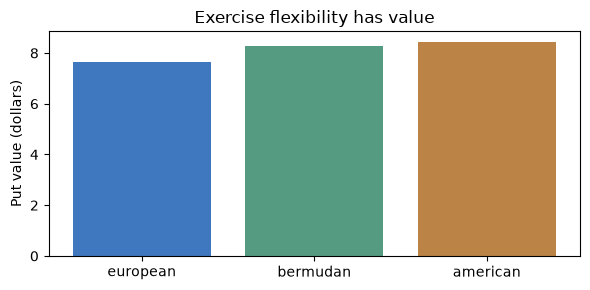

In [3]:
exercise_dates = [date(2025, 4, 1), date(2025, 7, 1), date(2025, 10, 1), expiry]
settings = dict(spot=95., strike=100., rate=.05, dividend_yield=0.,
                valuation_date=valuation, maturity_date=expiry, option_type="put",
                grid_points=81, time_steps=50, damping_steps=2, mesh_volatility=.20)
rows = []
for exercise in ("european", "bermudan", "american"):
    config = dict(settings, exercise=exercise,
                  exercise_dates=exercise_dates if exercise == "bermudan" else ())
    values = []
    for mode in ("full", "adjoint"):
        sigma = torch.tensor(.20, dtype=DTYPE, requires_grad=True)
        value = fd_vanilla(sigma, mode=mode, **config)
        sensitivity, = torch.autograd.grad(value, sigma)
        values.append((value.detach(), sensitivity.detach()))
    torch.testing.assert_close(values[0][0], values[1][0], rtol=1e-10, atol=1e-10)
    torch.testing.assert_close(values[0][1], values[1][1], rtol=1e-9, atol=1e-9)
    rows.append((exercise, values[1][0].item(), values[1][1].item()))
    print(f"{exercise:9s} put: {rows[-1][1]:.6f}; Vega: {rows[-1][2]:.6f}")
assert rows[2][1] >= rows[1][1] >= rows[0][1]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color=["#4078c0", "#559b82", "#bb8446"])
ax.set(ylabel="Put value (dollars)", title="Exercise flexibility has value")
fig.tight_layout()
plt.show()

## A constrained model parameter

A calibration parameter need not be volatility itself. Let
$\sigma(\theta)=\operatorname{softplus}(\theta)$ to keep volatility positive.
PyTorch composes $\partial V/\partial\sigma$ with
$\partial\sigma/\partial\theta$ without custom optimizer code.

In [4]:
theta = torch.tensor(-1.5, dtype=DTYPE, requires_grad=True)
sigma_model = torch.nn.functional.softplus(theta)
model_price = analytic_european(sigma_model, **market)
parameter_sensitivity, = torch.autograd.grad(model_price, theta)
assert parameter_sensitivity.item() > 0
print(f"sigma(theta)={sigma_model.item():.6f}; dV/dtheta={parameter_sensitivity.item():.6f}")
RESULT = {"call": price.item(), "delta": delta.item(), "vega": vega.item(),
          "gamma": gamma.item(), "early_exercise_puts": rows,
          "parameter_sensitivity": parameter_sensitivity.item()}

sigma(theta)=0.201413; dV/dtheta=7.062629


These finite-difference settings are modest teaching grids. Check mesh, time-step
and domain refinement for a production tolerance. Agreement between full AD and
adjoints validates their shared discrete problem; it does not bound error against
the continuous-time option price. [Capabilities and limits](../docs/capabilities.md)
describe the supported engines and derivatives.